# Normative Brain Modeling: Deep Quantile Regression with PyTorch MLP


A Multi-Layer Perceptron (MLP) using PyTorch to estimate normative statistical growth charts of brain volume across age and sex. 

This establishes an individualized normative reference range for brain range across the human lifespan.

In [2]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split

# Set random seeds for reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Device configuration (GPU / MPS / CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')
print(f"Using compute device: {device}")
print(f"PyTorch version: {torch.__version__}")

Using compute device: mps
PyTorch version: 2.5.1


## Load Data

Load the dataset saved from `preprocessing.ipynb`.
Both Age and Volume are standarized (z-score scaling) to ensure numerically stable gradients during gradient descent, while preserving the scaling parameters so predictions can be mapped back to original units.

In [3]:
# Load preprocessed dataset
data_path = "../data/processed/abide_normative_cleaned.csv"
df = pd.read_csv(data_path)

print(f"Loaded {len(df)} healthy control samples.")
print(df.head())
print("\nSummary statistics:")
print(df.describe())

# Save scaling parameters for inversion later
age_mean = df['AGE_AT_SCAN'].mean()
age_std = df['AGE_AT_SCAN'].std()
vol_mean = df['Volume'].mean()
vol_std = df['Volume'].std()

# Standardize continuous variables
df['Age_scaled'] = (df['AGE_AT_SCAN'] - age_mean) / age_std
df['Volume_scaled'] = (df['Volume'] - vol_mean) / vol_std

print(f"\nScaling parameters:\n  Age: mean={age_mean:.2f}, std={age_std:.2f}\n  Volume: mean={vol_mean:.2e}, std={vol_std:.2e}")

Loaded 176 healthy control samples.
   AGE_AT_SCAN  SEX        Volume
0        25.12    0  3.061224e-08
1        12.92    0  5.102041e-09
2        19.80    0 -2.551020e-08
3        12.15    0  5.102041e-09
4        14.77    0 -1.530612e-08

Summary statistics:
       AGE_AT_SCAN         SEX        Volume
count   176.000000  176.000000  1.760000e+02
mean     15.838554    0.170455 -8.140538e-10
std       4.776131    0.377104  2.314476e-08
min       8.200000    0.000000 -7.094595e-08
25%      12.822500    0.000000 -1.530612e-08
50%      15.000000    0.000000  1.285369e-16
75%      17.900000    0.000000  1.351351e-08
max      33.240000    1.000000  7.281553e-08

Scaling parameters:
  Age: mean=15.84, std=4.78
  Volume: mean=-8.14e-10, std=2.31e-08


## 3. PyTorch Dataset and DataLoaders

We package the features into a custom PyTorch `Dataset` and split the cohort into:
* **70% Training Set** (for model optimization)
* **15% Validation Set** (for tuning and early evaluation)
* **15% Test Set** (for unbiased final evaluation)

In [3]:
class NormativeBrainDataset(Dataset):
    def __init__(self, dataframe, feature_cols=['Age_scaled', 'SEX'], target_col='Volume_scaled'):
        self.X = torch.tensor(dataframe[feature_cols].values, dtype=torch.float32)
        self.y = torch.tensor(dataframe[target_col].values, dtype=torch.float32).unsqueeze(1)
        
    def __len__(self):
        return len(self.X)
    
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

full_dataset = NormativeBrainDataset(df)
total_samples = len(full_dataset)

# 70% train, 15% val, 15% test
train_size = int(0.70 * total_samples)
val_size = int(0.15 * total_samples)
test_size = total_samples - train_size - val_size

generator = torch.Generator().manual_seed(SEED)
train_dataset, val_dataset, test_dataset = random_split(
    full_dataset, [train_size, val_size, test_size], generator=generator
)

print(f"Dataset split:")
print(f"  Training:   {len(train_dataset)} samples")
print(f"  Validation: {len(val_dataset)} samples")
print(f"  Testing:    {len(test_dataset)} samples")

# Initialize DataLoaders
BATCH_SIZE = 16
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

Dataset split:
  Training:   123 samples
  Validation: 26 samples
  Testing:    27 samples


## 4. Deep Quantile MLP Architecture

### Monotonic Non-Crossing Quantile Design
A common issue in quantile neural networks is **quantile crossing**, where $q_{10}$ might accidentally predict a value higher than $q_{50}$. 

To mathematically prevent this, our network predicts:
1. The **Median ($q_{50}$)** directly from the output head.
2. Two non-negative offsets using `F.softplus`:
   $$\hat{y}_{10} = \hat{y}_{50} - 	ext{Softplus}(\Delta_{10})$$
   $$\hat{y}_{90} = \hat{y}_{50} + 	ext{Softplus}(\Delta_{90})$$

This guarantees that $\hat{y}_{10} \le \hat{y}_{50} \le \hat{y}_{90}$ for all inputs!

In [4]:
class NonCrossingQuantileMLP(nn.Module):
    def __init__(self, in_features=2, hidden_dim=64):
        super().__init__()
        # Shared non-linear representation backbone
        self.backbone = nn.Sequential(
            nn.Linear(in_features, hidden_dim),
            nn.GELU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.GELU(),
            nn.Dropout(0.1),
            nn.Linear(hidden_dim, 32),
            nn.GELU()
        )
        
        # Heads: Median (q50) and positive deltas for q10 and q90
        self.head_q50 = nn.Linear(32, 1)
        self.head_delta_lower = nn.Linear(32, 1)
        self.head_delta_upper = nn.Linear(32, 1)

    def forward(self, x):
        features = self.backbone(x)
        
        q50 = self.head_q50(features)
        # Softplus ensures non-negative offsets
        delta_lower = F.softplus(self.head_delta_lower(features))
        delta_upper = F.softplus(self.head_delta_upper(features))
        
        q10 = q50 - delta_lower
        q90 = q50 + delta_upper
        
        # Output tensor of shape [batch_size, 3]: columns are [q10, q50, q90]
        return torch.cat([q10, q50, q90], dim=1)

# Instantiate model
model = NonCrossingQuantileMLP(in_features=2, hidden_dim=64).to(device)
print(model)

# Test forward pass with dummy tensor
dummy_x = torch.randn(4, 2).to(device)
with torch.no_grad():
    dummy_out = model(dummy_x)
print(f"\nDummy forward output shape: {dummy_out.shape} ([batch_size, 3])")
print(f"Sample output [q10, q50, q90]:\n{dummy_out}")

NonCrossingQuantileMLP(
  (backbone): Sequential(
    (0): Linear(in_features=2, out_features=64, bias=True)
    (1): GELU(approximate='none')
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): GELU(approximate='none')
    (4): Dropout(p=0.1, inplace=False)
    (5): Linear(in_features=64, out_features=32, bias=True)
    (6): GELU(approximate='none')
  )
  (head_q50): Linear(in_features=32, out_features=1, bias=True)
  (head_delta_lower): Linear(in_features=32, out_features=1, bias=True)
  (head_delta_upper): Linear(in_features=32, out_features=1, bias=True)
)



Dummy forward output shape: torch.Size([4, 3]) ([batch_size, 3])


Sample output [q10, q50, q90]:
tensor([[-0.4934,  0.1620,  0.8919],
        [-0.5028,  0.1507,  0.8696],
        [-0.5197,  0.1374,  0.8517],
        [-0.5192,  0.1408,  0.8579]], device='mps:0')


## 5. Pinball (Quantile) Loss Function

The **Pinball (Check) Loss** asymmetric penalty function for a given quantile $\tau \in (0, 1)$ is defined as:
$$\mathcal{L}_\tau(y, \hat{y}_\tau) = \max\Big(\tau (y - \hat{y}_\tau), \ (\tau - 1)(y - \hat{y}_\tau)\Big)$$

The multi-quantile loss averages the pinball losses across all target quantiles $\tau \in \{0.10, 0.50, 0.90\}$.

In [5]:
class MultiQuantileLoss(nn.Module):
    def __init__(self, quantiles=[0.10, 0.50, 0.90]):
        super().__init__()
        self.quantiles = quantiles

    def forward(self, preds, target):
        # preds: [batch_size, num_quantiles]
        # target: [batch_size, 1]
        losses = []
        for i, q in enumerate(self.quantiles):
            pred_q = preds[:, i:i+1]
            error = target - pred_q
            loss_q = torch.max(q * error, (q - 1.0) * error)
            losses.append(loss_q.mean())
        return torch.stack(losses).mean()

criterion = MultiQuantileLoss(quantiles=[0.10, 0.50, 0.90])

## 6. Model Training Loop

We train the model using **AdamW** with a weight decay regularizer and a **ReduceLROnPlateau** learning rate scheduler to converge smoothly.

In [6]:
EPOCHS = 120
LR = 1e-3

optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=15)

train_loss_history = []
val_loss_history = []

for epoch in range(1, EPOCHS + 1):
    # Training phase
    model.train()
    running_train_loss = 0.0
    for batch_x, batch_y in train_loader:
        batch_x, batch_y = batch_x.to(device), batch_y.to(device)
        
        optimizer.zero_grad()
        preds = model(batch_x)
        loss = criterion(preds, batch_y)
        loss.backward()
        optimizer.step()
        
        running_train_loss += loss.item() * batch_x.size(0)
        
    train_loss = running_train_loss / len(train_dataset)
    train_loss_history.append(train_loss)
    
    # Validation phase
    model.eval()
    running_val_loss = 0.0
    with torch.no_grad():
        for batch_x, batch_y in val_loader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)
            preds = model(batch_x)
            val_loss = criterion(preds, batch_y)
            running_val_loss += val_loss.item() * batch_x.size(0)
            
    val_loss = running_val_loss / len(val_dataset)
    val_loss_history.append(val_loss)
    scheduler.step(val_loss)
    
    if epoch % 20 == 0 or epoch == 1:
        current_lr = optimizer.param_groups[0]['lr']
        print(f"Epoch [{epoch:03d}/{EPOCHS:03d}] | Train Loss: {train_loss:.5f} | Val Loss: {val_loss:.5f} | LR: {current_lr:.6f}")

Epoch [001/120] | Train Loss: 0.27348 | Val Loss: 0.27145 | LR: 0.001000


Epoch [020/120] | Train Loss: 0.23642 | Val Loss: 0.29502 | LR: 0.000500


Epoch [040/120] | Train Loss: 0.23555 | Val Loss: 0.30271 | LR: 0.000250


Epoch [060/120] | Train Loss: 0.23380 | Val Loss: 0.29930 | LR: 0.000125


Epoch [080/120] | Train Loss: 0.23396 | Val Loss: 0.30207 | LR: 0.000063


Epoch [100/120] | Train Loss: 0.23150 | Val Loss: 0.30234 | LR: 0.000016


Epoch [120/120] | Train Loss: 0.23323 | Val Loss: 0.30168 | LR: 0.000008


## 7. Training Diagnostics

Visualizing convergence of the training and validation quantile losses across epochs.

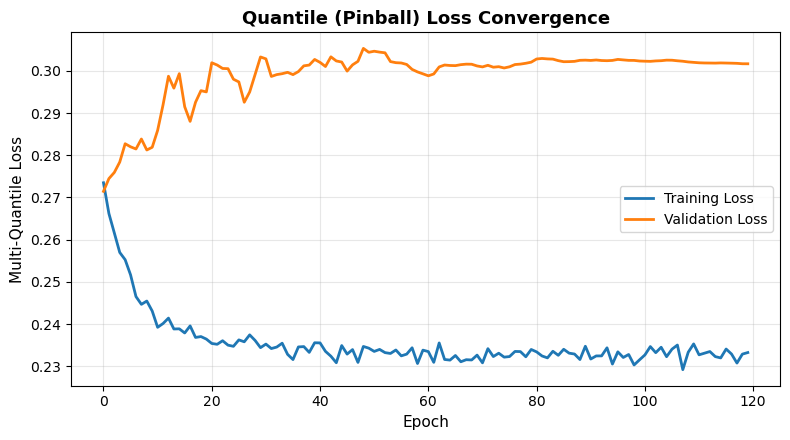

In [7]:
plt.figure(figsize=(8, 4.5))
plt.plot(train_loss_history, label='Training Loss', color='#1f77b4', lw=2)
plt.plot(val_loss_history, label='Validation Loss', color='#ff7f0e', lw=2)
plt.title('Quantile (Pinball) Loss Convergence', fontsize=13, fontweight='bold')
plt.xlabel('Epoch', fontsize=11)
plt.ylabel('Multi-Quantile Loss', fontsize=11)
plt.grid(True, alpha=0.3)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

## 8. Test Set Evaluation & Empirical Coverage

To verify that the quantiles are well-calibrated:
* Approximately **10%** of test observations should fall below $\hat{q}_{10}$.
* Approximately **50%** of test observations should fall below $\hat{q}_{50}$.
* Approximately **90%** of test observations should fall below $\hat{q}_{90}$.
* Approximately **80%** should fall inside the normative corridor $[\hat{q}_{10}, \hat{q}_{90}]$.

In [8]:
model.eval()
test_loss = 0.0
all_preds = []
all_targets = []

with torch.no_grad():
    for batch_x, batch_y in test_loader:
        batch_x, batch_y = batch_x.to(device), batch_y.to(device)
        preds = model(batch_x)
        loss = criterion(preds, batch_y)
        test_loss += loss.item() * batch_x.size(0)
        
        all_preds.append(preds.cpu())
        all_targets.append(batch_y.cpu())

test_loss /= len(test_dataset)
all_preds = torch.cat(all_preds, dim=0).numpy()
all_targets = torch.cat(all_targets, dim=0).numpy()

# Calculate empirical coverage
below_q10 = np.mean(all_targets <= all_preds[:, 0:1]) * 100
below_q50 = np.mean(all_targets <= all_preds[:, 1:2]) * 100
below_q90 = np.mean(all_targets <= all_preds[:, 2:3]) * 100
in_corridor = np.mean((all_targets >= all_preds[:, 0:1]) & (all_targets <= all_preds[:, 2:3])) * 100

print(f"Test Set Multi-Quantile Loss: {test_loss:.5f}")
print("\nEmpirical Calibration on Test Set:")
print(f"  Observed <= 10th centile: {below_q10:.1f}% (Target: 10.0%)")
print(f"  Observed <= 50th centile: {below_q50:.1f}% (Target: 50.0%)")
print(f"  Observed <= 90th centile: {below_q90:.1f}% (Target: 90.0%)")
print(f"  Observed within [10th, 90th] corridor: {in_corridor:.1f}% (Target: 80.0%)")

Test Set Multi-Quantile Loss: 0.23322

Empirical Calibration on Test Set:
  Observed <= 10th centile: 11.1% (Target: 10.0%)
  Observed <= 50th centile: 48.1% (Target: 50.0%)
  Observed <= 90th centile: 88.9% (Target: 90.0%)
  Observed within [10th, 90th] corridor: 77.8% (Target: 80.0%)


## 9. Normative Brain Centile Growth Charts

Generating continuous normative trajectories across the lifespan for **Males (`Sex = 0`)** and **Females (`Sex = 1`)**, mapping predicted values back to original units.

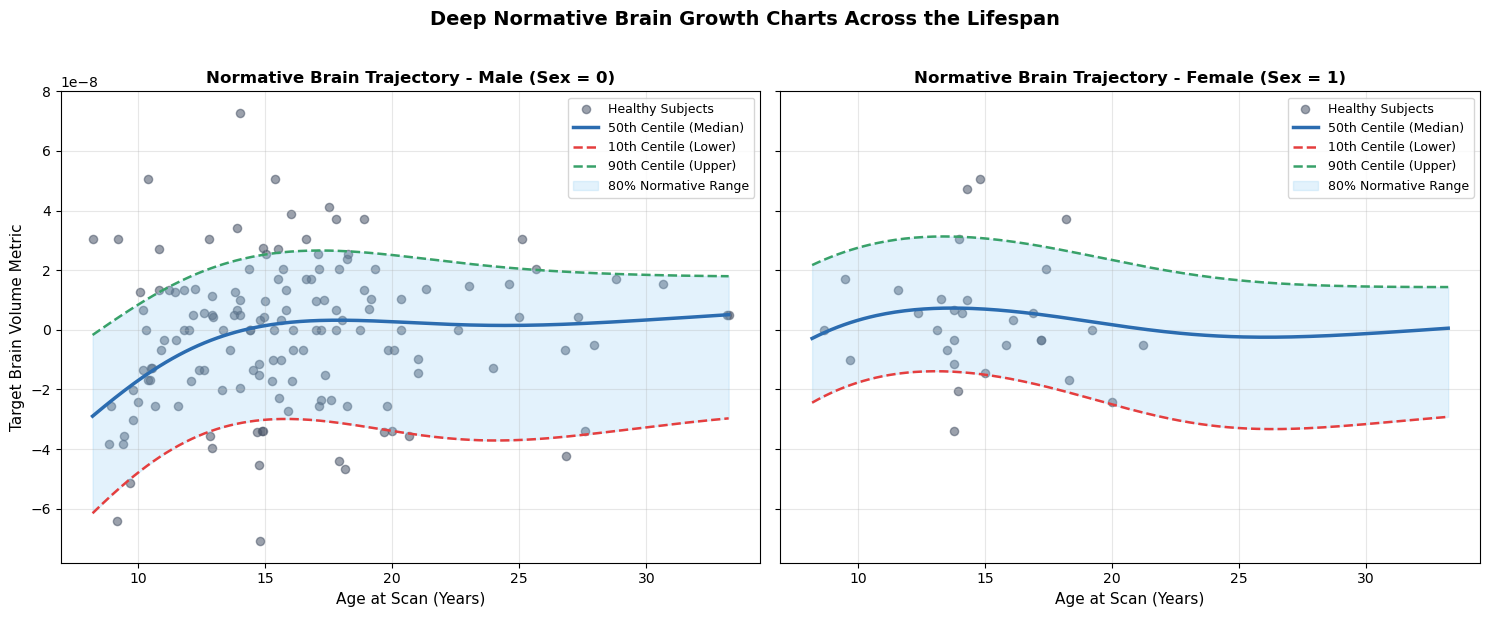

In [9]:
# Generate continuous age grid across the sampled range
age_grid = np.linspace(df['AGE_AT_SCAN'].min(), df['AGE_AT_SCAN'].max(), 200)
age_grid_scaled = (age_grid - age_mean) / age_std

fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)
sex_labels = {0: 'Male (Sex = 0)', 1: 'Female (Sex = 1)'}

model.eval()
with torch.no_grad():
    for sex_val, ax in zip([0, 1], axes):
        # Create input tensor for this sex across the age grid
        grid_features = np.column_stack([age_grid_scaled, np.full_like(age_grid_scaled, sex_val)])
        grid_tensor = torch.tensor(grid_features, dtype=torch.float32).to(device)
        
        preds_scaled = model(grid_tensor).cpu().numpy()
        
        # Invert scaling back to original Volume units
        preds_orig = preds_scaled * vol_std + vol_mean
        q10_orig = preds_orig[:, 0]
        q50_orig = preds_orig[:, 1]
        q90_orig = preds_orig[:, 2]
        
        # Plot subject data points
        subset = df[df['SEX'] == sex_val]
        ax.scatter(subset['AGE_AT_SCAN'], subset['Volume'], color='#4a5568', alpha=0.55, s=35, label='Healthy Subjects')
        
        # Plot centile curves
        ax.plot(age_grid, q50_orig, color='#2b6cb0', lw=2.5, label='50th Centile (Median)')
        ax.plot(age_grid, q10_orig, color='#e53e3e', lw=1.8, linestyle='--', label='10th Centile (Lower)')
        ax.plot(age_grid, q90_orig, color='#38a169', lw=1.8, linestyle='--', label='90th Centile (Upper)')
        
        # Fill normative corridor
        ax.fill_between(age_grid, q10_orig, q90_orig, color='#90cdf4', alpha=0.25, label='80% Normative Range')
        
        ax.set_title(f"Normative Brain Trajectory - {sex_labels[sex_val]}", fontsize=12, fontweight='bold')
        ax.set_xlabel("Age at Scan (Years)", fontsize=11)
        ax.grid(True, alpha=0.3)
        ax.legend(loc='upper right', frameon=True, fontsize=9)

axes[0].set_ylabel("Target Brain Volume Metric", fontsize=11)
plt.suptitle("Deep Normative Brain Growth Charts Across the Lifespan", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## 10. Clinical Utility: Individual Centile Deviation Scoring

In a clinical setting, an individual patient scan is scored against the normative corridor to detect whether they exhibit typical structure or atypical deviation.

In [10]:
def evaluate_patient_scan(patient_age: float, patient_sex: int, patient_volume: float):
    # Scale patient input
    p_age_scaled = (patient_age - age_mean) / age_std
    p_input = torch.tensor([[p_age_scaled, float(patient_sex)]], dtype=torch.float32).to(device)
    
    model.eval()
    with torch.no_grad():
        preds = model(p_input).cpu().numpy()[0]
        preds_orig = preds * vol_std + vol_mean
        q10, q50, q90 = preds_orig[0], preds_orig[1], preds_orig[2]
        
    print(f"--- Clinical Evaluation Report ---")
    print(f"Demographics: Age {patient_age:.1f} | Sex: {'Female' if patient_sex == 1 else 'Male'}")
    print(f"Observed Volume: {patient_volume:.2e}")
    print(f"Normative 10th Centile: {q10:.2e}")
    print(f"Normative 50th Centile (Median): {q50:.2e}")
    print(f"Normative 90th Centile: {q90:.2e}")
    
    if patient_volume < q10:
        status = "⚠️ ATYPICAL (Below 10th Centile - Accelerated Atrophy / Micro-deviation)"
    elif patient_volume > q90:
        status = "⚠️ ATYPICAL (Above 90th Centile - Enlargement / Macro-deviation)"
    else:
        status = "✅ TYPICAL (Within normative 10th-90th population corridor)"
        
    print(f"Clinical Status: {status}")

# Example: evaluate a 24-year-old male
evaluate_patient_scan(patient_age=24.0, patient_sex=0, patient_volume=df['Volume'].iloc[0])

--- Clinical Evaluation Report ---
Demographics: Age 24.0 | Sex: Male
Observed Volume: 3.06e-08
Normative 10th Centile: -3.71e-08
Normative 50th Centile (Median): 1.48e-09
Normative 90th Centile: 2.13e-08
Clinical Status: ⚠️ ATYPICAL (Above 90th Centile - Enlargement / Macro-deviation)


## 11. Save Trained Model Weights

Saving the trained model checkpoint to disk for future inference or deployment.

In [11]:
os.makedirs("../models", exist_ok=True)
model_path = "../models/normative_mlp_checkpoint.pt"
torch.save({
    'model_state_dict': model.state_dict(),
    'age_mean': age_mean,
    'age_std': age_std,
    'vol_mean': vol_mean,
    'vol_std': vol_std,
    'quantiles': [0.10, 0.50, 0.90]
}, model_path)
print(f"Trained model checkpoint saved successfully to: {model_path}")

Trained model checkpoint saved successfully to: ../models/normative_mlp_checkpoint.pt
